In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

data_path = "../data/processed/mental-heath-in-tech-2016-clean.csv"
FIGURES_PATH = "../reports/figures/data_preparation"

sns.set_theme(style="whitegrid", context="notebook")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

warnings.filterwarnings("default", category=FutureWarning)

In [ ]:
df_clean = pd.read_csv(data_path)

df_clean.head()

,self_employed,company_size,tech_company,tech_role,mh_benefits,mh_options_awareness,mh_formal_discussion,mh_resources_offered,mh_anonymity_protected,mh_medical_leave_ease,mh_discussion_consequences,ph_discussion_consequences,mh_comfort_coworkers,mh_comfort_supervisor,mh_vs_ph_seriousness,observed_mh_consequences,medical_coverage_mh,know_external_resources,reveal_mh_clients,client_reveal_neg_impact,reveal_mh_coworkers,coworker_reveal_neg_impact,mh_productivity_affected,mh_productivity_pct,has_previous_employers,prev_mh_benefits,prev_mh_awareness,prev_mh_discussion,prev_mh_resources,prev_mh_anonymity,prev_mh_consequences,prev_ph_consequences,prev_willingness_coworkers,prev_willingness_supervisor,prev_mh_vs_ph_seriousness,prev_observed_mh_consequences,interview_ph_reveal,interview_ph_reveal_why,interview_mh_reveal,interview_mh_reveal_why,mh_hurt_career,coworker_negative_view,share_with_friends_family,observed_bad_mh_handling,observed_bad_handling_impact,family_history_mh,past_mh_disorder,current_mh_disorder,current_diagnosed_conditions,suspected_conditions,diagnosed_by_pro,pro_diagnosed_conditions,sought_mh_treatment,mh_interference_treated,mh_interference_untreated,age,gender,country_live,us_state_live,country_work,us_state_work,work_position,work_remote
0,0,26-100,1.0,NaN,Not eligible for coverage / N/A,NaN,No,No,I don't know,Very easy,No,No,Maybe,Yes,I don't know,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,"No, none did",N/A (not currently aware),I don't know,None did,I don't know,Some of them,None of them,Some of my previous employers,Some of my previous employers,I don't know,None of them,Maybe,NaN,Maybe,NaN,Maybe,"No, I don't think they would",Somewhat open,No,NaN,No,Yes,No,NaN,NaN,Yes,"Anxiety Disorder (Generalized, Social, Phobia, etc)",0,Not applicable to me,Not applicable to me,39,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Sometimes
1,0,6-25,1.0,NaN,No,Yes,Yes,Yes,Yes,Somewhat easy,No,No,Maybe,Yes,Yes,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,"Yes, they all did",I was aware of some,None did,Some did,"Yes, always",None of them,None of them,"No, at none of my previous employers",Some of my previous employers,Some did,None of them,Maybe,It would depend on the health issue. If there is a health issue that would not immediately affec...,No,"While mental health has become a more prominent issue recently, I feel like there is still a lot...","No, I don't think it would","No, I don't think they would",Somewhat open,No,NaN,Yes,Yes,Yes,"Anxiety Disorder (Generalized, Social, Phobia, etc)|Mood Disorder (Depression, Bipolar Disorder,...",NaN,Yes,"Anxiety Disorder (Generalized, Social, Phobia, etc)|Mood Disorder (Depression, Bipolar Disorder,...",1,Rarely,Sometimes,29,male,United States of America,Illinois,United States of America,Illinois,Back-end Developer|Front-end Developer,Never
2,0,6-25,1.0,NaN,No,NaN,No,No,I don't know,Neither easy nor difficult,Maybe,No,Maybe,Maybe,I don't know,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,"No, none did",N/A (not currently aware),None did,Some did,I don't know,I don't know,Some of them,Some of my previous employers,I don't know,I don't know,Some of them,Yes,"They would provable need to know, to Judge if I can do my job or not.",Yes,"Stigma, mainly.",Maybe,Maybe,Somewhat open,Maybe/Not sure,Yes,No,Maybe,No,NaN,NaN,No,NaN,1,Not applicable to me,Not applicable to me,38,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Always
3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,"Yes, I know several","Sometimes, if it comes up",I'm not sure,"Sometimes, if it comes up",I'm not sure,Yes,1-25%,1,Some did,N/A (not currently aware),None did,None did,I don't know,Some of them,Some of them,Some of my previous employers,Some of my previous employers,I don't know,Some of them,Yes,"old back injury, doesn't cause me many issues but occasionally impacts my ability to work at desk",Maybe,would not if I was not 100% sure that the disclosure would not affect my application,"Yes, I think

In [5]:
df_clean.shape

(1433, 63)

In [8]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1433 entries, 0 to 1432
Data columns (total 63 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   self_employed                  1433 non-null   int64  
 1   company_size                   1146 non-null   str    
 2   tech_company                   1146 non-null   float64
 3   tech_role                      263 non-null    float64
 4   mh_benefits                    1146 non-null   str    
 5   mh_options_awareness           1013 non-null   str    
 6   mh_formal_discussion           1146 non-null   str    
 7   mh_resources_offered           1146 non-null   str    
 8   mh_anonymity_protected         1146 non-null   str    
 9   mh_medical_leave_ease          1146 non-null   str    
 10  mh_discussion_consequences     1146 non-null   str    
 11  ph_discussion_consequences     1146 non-null   str    
 12  mh_comfort_coworkers           1146 non-null   str    
 13 

In [9]:
binary = [
    # Survey Routing Gatekeepers: Strict 1/0 variables that dynamically change 
    # which sections of the survey a respondent is served.
    "self_employed?",  # Separates freelancers/business owners from enterprise employees
    "has_previous_employer",  # If 0, skips all historical workplace questions
]

nominal = [
    # Current Employer / Workplace Dynamics
    # Tracks basic company ecosystem attributes and high-level structure.
    "tech_company",
    "tech_role",
    
    # Workplace Benefits & Awareness
    # Evaluates the visibility and availability of corporate mental health support.
    "mh_benefits",
    "mh_options_awareness",
    "mh_formal_discussion",
    "mh_resources_offered",
    "mh_anonymity_protected",
    
    # Internal Psychological Safety & Workplace Culture
    # Captures current employee comfort levels and perceived corporate blowback.
    "mh_discussion_consequences",
    "ph_discussion_consequences",
    "mh_comfort_coworkers",
    "mh_comfort_supervisor",
    "mh_vs_ph_seriousness",
    "observed_mh_consequences",
    "medical_coverage_mh",
    "know_external_resources",
    
    # Disclosures & Productivity Impact
    # Conditional logic loops evaluating external interactions vs internal realities.
    "reveal_mh_clients",
    "client_reveal_neg_impact",
    "reveal_mh_coworkers",
    "coworker_reveal_neg_impact",
    "mh_productivity_affected",
    
    # Previous Employers (Historical Workplace Context)
    # Mirror questions to current employer dynamics, evaluating past career environments.
    "prev_mh_benefits",
    "prev_mh_awareness",
    "prev_mh_discussion",
    "prev_mh_resources",
    "prev_mh_anonymity",
    "prev_mh_consequences",
    "prev_ph_consequences",
    "prev_willingness_coworkers",
    "prev_willingness_supervisor",
    "prev_mh_vs_ph_seriousness",
    "prev_observed_mh_consequences",
    
    # Interviews, Career, Stigma
    # Assesses prospective hiring biases, public stigma, and general industry barriers.
    "interview_ph_reveal",
    "interview_mh_reveal",
    "mh_hurt_career",
    "coworker_negative_view",
    "observed_bad_mh_handling",
    
    # Medical History & Diagnostics
    # Personal health indicators and multi-select condition buckets (e.g., Anxiety, Depression, ADHD).
    "family_history_mh",
    "past_mh_disorder",
    "current_mh_disorder",
    "current_diagnosed_conditions",
    "suspected_conditions",
    "diagnosed_by_pro",
    "pro_diagnosed_conditions",
    "sought_mh_treatment",
    
    # Demographics & Work Type
    # High-level regional, biological, and technical tracking features.
    "country_live",
    "us_state_live",
    "country_work",
    "us_state_work",
    "work_position",
    "work_remote"
]

ordinal = [
    # Sized & Scaled Continuous Categories
    # Features that follow a clear linear order, ranging from company size brackets 
    # to sequential degrees of frequency and willingness scales.
    "company_size",  # Company size ranges (e.g., 1-5 to 1000+)
    "mh_medical_leave_ease",  # Ease scale (Very Easy to Very Difficult)
    "mh_productivity_pct",  # Impact brackets (1-20% to 81-100%)
    "share_with_friends_family",  # Numeric Likert scale (0-10 or 1-5 scale)
    "observed_bad_handling_impact",  # Impact magnitude scale
    "mh_interference_treated",  # Frequency scale (Never, Rarely, Sometimes, Often)
    "mh_interference_untreated"   # Frequency scale (Never, Rarely, Sometimes, Often)
]

numeric = [
    # Continuous Mathematical Metrics
    "age"  # Numerical integer value; contains outlier entry noise needing clean-up filters
]

free_text = [
    # Qualitative / Unstructured String Inputs
    # Open-ended responses clarifying specific interview-stage safety boundaries.
    "interview_ph_reveal_why",    # Context for physical health disclosures during prospective interviews
    "interview_mh_reveal_why"  # Context for mental health disclosures during prospective interviews
]

routing_gates = {
    # 1. Employment Status Switch
    "self_employed": [
        "tech_company",
        "tech_role",
        "mh_benefits",
        "mh_options_awareness",
        "mh_formal_discussion",
        "mh_resources_offered",
        "mh_anonymity_protected",
        "mh_medical_leave_ease",
        "mh_discussion_consequences",
        "ph_discussion_consequences",
        "mh_comfort_coworkers",
        "mh_comfort_supervisor",
        "mh_vs_ph_seriousness",
        "observed_mh_consequences",
        "medical_coverage_mh" # Only asked if Self-Employed = 1
    ],
    
    # 2. Historical Career Switch
    "has_previous_employers": [
        "prev_mh_benefits",
        "prev_mh_awareness",
        "prev_mh_discussion",
        "prev_mh_resources",
        "prev_mh_anonymity",
        "prev_mh_consequences",
        "prev_ph_consequences",
        "prev_willingness_coworkers",
        "prev_willingness_supervisor",
        "prev_mh_vs_ph_seriousness",
        "prev_observed_mh_consequences"
    ],
    
    # 3. Personal History Switch
    "current_mh_disorder": [
        "current_diagnosed_conditions",
        "suspected_conditions",
        "mh_productivity_affected"
    ],
    
    # 4. Productivity Switch
    "mh_productivity_affected": [
        "mh_productivity_pct"
    ],
    
    # 5. Professional Medical Validation Switch
    "diagnosed_by_pro": [
        "pro_diagnosed_conditions"
    ]
}

selected_features = [
    "self_employed",
    "has_previous_employers",
    "tech_company",
    "work_remote",
    "company_size",
    "mh_benefits",
    "mh_medical_leave_ease",
    "mh_vs_ph_seriousness",
    "mh_discussion_consequences",
    "mh_comfort_coworkers",
    "mh_comfort_supervisor",
    "interview_mh_reveal",
    "mh_hurt_career",
    "family_history_mh",
    "current_mh_disorder",
    "sought_mh_treatment",
    "age"
]

Handle pipe separated entries

In [13]:
# PRE-GATE CLEANUP: Handle pipe-separated multi-selects and residual missing strings
pipe_columns = [
    "current_diagnosed_conditions",
    "suspected_conditions",
    "pro_diagnosed_conditions",
    "work_position",
]

for col in pipe_columns:
    if col in df_clean.columns:
        # Fill absolute blanks for respondents who didn't select any options or skipped
        df_clean[col] = df_clean[col].fillna("None / Not Answered")
        # Strip extra spaces around pipe separators for consistency
        df_clean[col] = df_clean[col].astype(str).apply(
            lambda x: " | ".join(
                [item.strip() for item in x.split("|")]
            ) if x != "None / Not Answered" else x
        )

    # Catch-all for remaining object/string columns that still have tru NaNs
    for col in df_clean.select_dtypes(include=["object", "str"]).columns:
        if df_clean[col].isna().sum() > 0:
            df_clean[col] = df_clean[col].fillna("Not Applicable / Unspecified")

In [16]:
# Check unique counts and total non-null counts across the dataframe
print("--- UNIQUE COUNTS PER COLUMN ---")
print(df_clean.nunique())

# Inspect specific value counts for the pipe-separated columns 
# to verify that 'None / Not Answered' and pipe formats are correct

for col in pipe_columns:
    if col in df_clean.columns:
        print(f"\n--- Value Counts for: {col} ---")
        # Print top 5 most frequent responses to verify cleaning
        print(df_clean[col].value_counts().head(5))

--- UNIQUE COUNTS PER COLUMN ---
self_employed                       2
company_size                        7
tech_company                        3
tech_role                           3
mh_benefits                         5
mh_options_awareness                5
mh_formal_discussion                4
mh_resources_offered                4
mh_anonymity_protected              4
mh_medical_leave_ease               7
mh_discussion_consequences          4
ph_discussion_consequences          4
mh_comfort_coworkers                4
mh_comfort_supervisor               4
mh_vs_ph_seriousness                4
observed_mh_consequences            3
medical_coverage_mh                 2
know_external_resources             4
reveal_mh_clients                   6
client_reveal_neg_impact            4
reveal_mh_coworkers                 6
coworker_reveal_neg_impact          5
mh_productivity_affected            6
mh_productivity_pct                 6
has_previous_employers              2
prev_mh_benefits 

Handle routing gates missing values

In [45]:
# GATE 1: Employment Status Switch
# If self_employed == 1, they have no corporate employer.

gate_1_cols = routing_gates["self_employed"]

for col in gate_1_cols:
    if col in df_clean.columns:
        # For numeric or float columns, fill with -1 to preserve integer capability later
        if df_clean[col].dtype in ["float64", "int64"]:
            df_clean.loc[
                df_clean["self_employed"] == 1, col
            ] = df_clean.loc[
                df_clean["self_employed"] == 1, col
            ].fillna(-1)
        # For string columns fill with "Not Applicable"
        else:
            df_clean.loc[
                df_clean["self_employed"] == 1, col
            ] = df_clean.loc[
                df_clean["self_employed"] == 1, col
            ].fillna("Not Applicable")



# GATE 2: Historical Career Switch
# If has_previous_emplotyers == 0, they never had a past employer.

gate_2_cols = routing_gates["has_previous_employers"]

for col in gate_2_cols:
    if col in df_clean.columns:
        df_clean.loc[
            df_clean["has_previous_employers"] == 0, col
        ] = df_clean.loc[
            df_clean["has_previous_employers"] == 0, col
        ].fillna("Not Applicable")



# GATE 3: Personal History Switch
# If current_mh_disorder is "No", they skip specific condition sub-questions.

gate_3_cols = routing_gates["current_mh_disorder"]

for col in gate_3_cols:
    if col in df_clean.columns:
        df_clean.loc[
            df_clean["current_mh_disorder"] == "No", col
        ] = df_clean.loc[
            df_clean["current_mh_disorder"] == "No", col
        ].fillna("No condition")



# GATE 4: Productivity Switch
# If mh_productivity_affected is "No" or "Not Applicable", percentage is blank.

gate_4_cols = routing_gates["mh_productivity_affected"]

for col in gate_4_cols:
    if col in df_clean.columns:
        df_clean.loc[
            df_clean["mh_productivity_affected"].isin(["No", "Not Applicable"]), col
        ] = df_clean.loc[
            df_clean["mh_productivity_affected"].isin(["No", "Not Applicable"]), col
        ].fillna("0%")



# GATE 5: Professional Medical Validation Switch
# If diagnosed_by_pro is "No", they won't have a professional diagnosis breakdown.

gate_5_cols = routing_gates["diagnosed_by_pro"]

for col in gate_5_cols:
    if col in df_clean.columns:
        df_clean.loc[
            df_clean["diagnosed_by_pro"] == "No", col
        ] = df_clean.loc[
            df_clean["diagnosed_by_pro"] == "No", col
        ].fillna("No professional diagnosis")

# Fill remaining NaNs for tech_role and medical_coverage_mh based on their structural logic
df_clean["tech_role"] = df_clean["tech_role"].astype(str).fillna("Not Applicable / Non-Tech")
df_clean["medical_coverage_mh"] = df_clean["medical_coverage_mh"].astype(str).fillna("Not Applicable (Corporate Employee)")

# Check remaining missing counts acrosse these specific gate columns
print(
    df_clean[
        gate_1_cols + gate_2_cols + gate_3_cols + gate_4_cols + gate_5_cols
    ].isna().sum()
)

tech_company                     0
tech_role                        0
mh_benefits                      0
mh_options_awareness             0
mh_formal_discussion             0
mh_resources_offered             0
mh_anonymity_protected           0
mh_medical_leave_ease            0
mh_discussion_consequences       0
ph_discussion_consequences       0
mh_comfort_coworkers             0
mh_comfort_supervisor            0
mh_vs_ph_seriousness             0
observed_mh_consequences         0
medical_coverage_mh              0
prev_mh_benefits                 0
prev_mh_awareness                0
prev_mh_discussion               0
prev_mh_resources                0
prev_mh_anonymity                0
prev_mh_consequences             0
prev_ph_consequences             0
prev_willingness_coworkers       0
prev_willingness_supervisor      0
prev_mh_vs_ph_seriousness        0
prev_observed_mh_consequences    0
current_diagnosed_conditions     0
suspected_conditions             0
mh_productivity_affe

In [43]:
# Check if "nan" strings are hiding as text categories
print(df_clean["medical_coverage_mh"].value_counts(dropna=False).head())
print(df_clean["tech_role"].value_counts(dropna=False).head())

medical_coverage_mh
<NA>    1146
1        185
0        102
Name: count, dtype: Int64
tech_role
<NA>    883
-1      287
1       248
0        15
Name: count, dtype: Int64


In [22]:
# Verify that the routing gates successfully removed remaining NaNs
gate_cols_to_verify = (
    routing_gates["self_employed"] + 
    routing_gates["has_previous_employers"] + 
    routing_gates["current_mh_disorder"] + 
    routing_gates["mh_productivity_affected"] + 
    routing_gates["diagnosed_by_pro"]
)

print("\n--- Remaining NaNs in Gate-Controlled Columns ---")
print(df_clean[gate_cols_to_verify].isna().sum()[lambda x: x > 0])


--- Remaining NaNs in Gate-Controlled Columns ---
Series([], dtype: int64)


In [26]:
# Ensure core binary & numeric columns are numeric first
numeric_cols = [
    "self_employed",
    "has_previous_employers",
    "sought_mh_treatment",
    "tech_company",
    "tech_role",
    "medical_coverage_mh",
    "age"
]

for col in numeric_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Keep age strictly as int64
if "age" in df_clean.columns:
    df_clean["age"] = df_clean["age"].astype("int64")

# Convert binary float columns (0.0/1.0) into clean integer flags (0/1)
binary_float_cols = ["tech_company", "tech_role", "medical_coverage_mh"]
for col in binary_float_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype("Int64")

# Convert all remaining text/object columns to proper pandas 'category' dtype
for col in df_clean.select_dtypes(include=["object", "str"]).columns:
    df_clean[col] = df_clean[col].astype("category")

# Verify the finalized dtypes across the dataset
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1433 entries, 0 to 1432
Data columns (total 63 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   self_employed                  1433 non-null   int64   
 1   company_size                   1433 non-null   category
 2   tech_company                   1433 non-null   Int64   
 3   tech_role                      550 non-null    Int64   
 4   mh_benefits                    1433 non-null   category
 5   mh_options_awareness           1433 non-null   category
 6   mh_formal_discussion           1433 non-null   category
 7   mh_resources_offered           1433 non-null   category
 8   mh_anonymity_protected         1433 non-null   category
 9   mh_medical_leave_ease          1433 non-null   category
 10  mh_discussion_consequences     1433 non-null   category
 11  ph_discussion_consequences     1433 non-null   category
 12  mh_comfort_coworkers           1433 non-null 

In [ ]:
selected_features = [
    "self_employed",
    "has_previous_employers",
    "tech_company",
    "work_remote",
    "company_size",
    "mh_benefits",
    "mh_medical_leave_ease",
    "mh_vs_ph_seriousness",
    "mh_discussion_consequences",
    "mh_comfort_coworkers",
    "mh_comfort_supervisor",
    "interview_mh_reveal",
    "mh_hurt_career",
    "family_history_mh",
    "current_mh_disorder",
    "sought_mh_treatment",
    "age"
]

In [28]:
df_clean["age"].describe()

count    1433.000000
mean       34.286113
std        11.290931
min         3.000000
25%        28.000000
50%        33.000000
75%        39.000000
max       323.000000
Name: age, dtype: float64

Dataset Age Statistics -> Mean: 34.29 | Median: 33.00


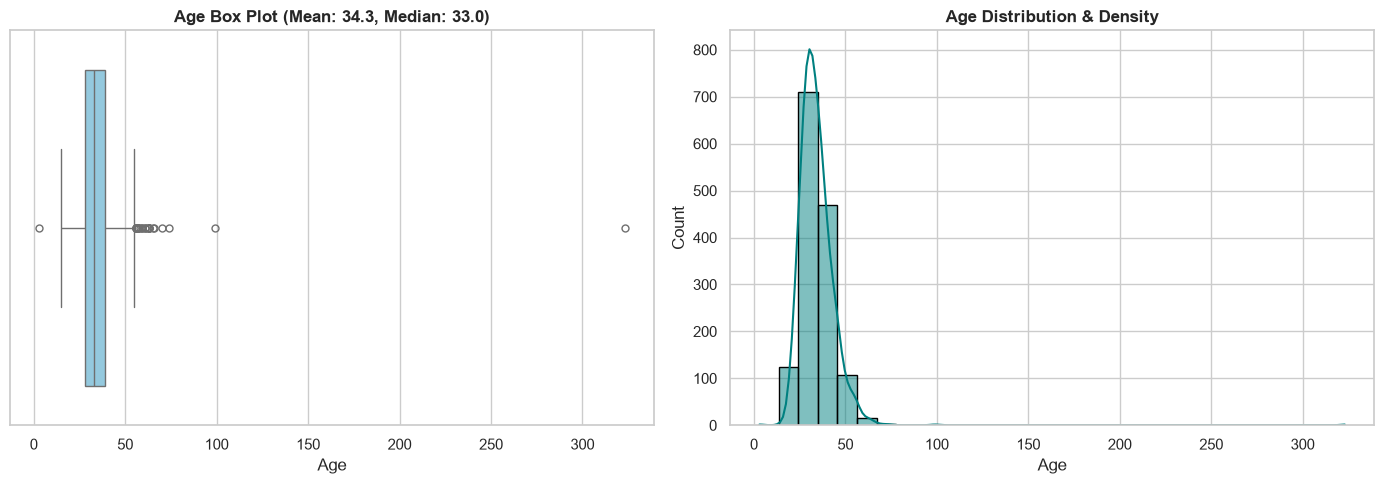

In [35]:
# 1. Calculate statistical metrics
mean_age = df_clean["age"].mean()
median_age = df_clean["age"].median()

print(f"Dataset Age Statistics -> Mean: {mean_age:.2f} | Median: {median_age:.2f}")

# 2. Create the figure with two subplots (Boxplot + Hist/KDE) without cutoff lines
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box Plot
sns.boxplot(x=df_clean["age"], ax=axes[0], color="skyblue", fliersize=5)
axes[0].set_title(f"Age Box Plot (Mean: {mean_age:.1f}, Median: {median_age:.1f})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Age")

# Histogram / KDE Plot
sns.histplot(data=df_clean, x="age", kde=True, ax=axes[1], color="teal", bins=30, edgecolor="black")
axes[1].set_title(f"Age Distribution & Density", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

Imputation Value (Median of valid ages 18-75): 33.0
Total outlier/invalid age entries flagged & imputed: 5
Cleaned Age Statistics -> Mean: 34.08 | Median: 33.00


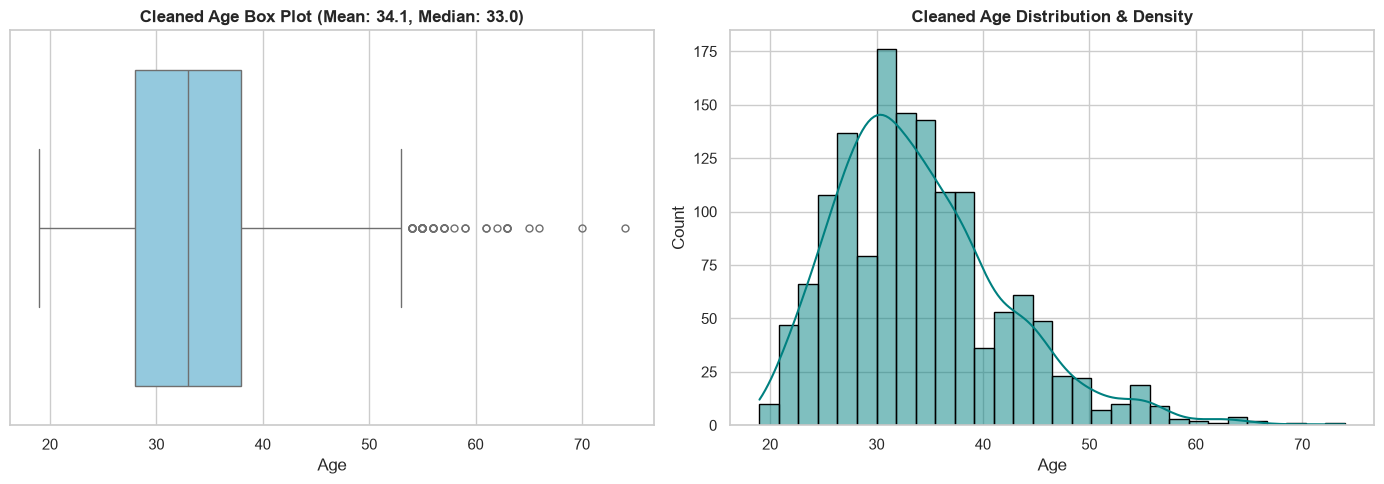

In [42]:
# 1. Calculate the median age based on valid bounds or overall data
# (Using valid working ages between 18 and 75 to get a realistic median)
valid_ages = df_clean["age"][(df_clean["age"] >= 18) & (df_clean["age"] <= 75)]
median_age = valid_ages.median()

print(f"Imputation Value (Median of valid ages 18-75): {median_age}")

# 2. Flag and impute values below 18 and above 75 with the median
outlier_mask = (df_clean["age"] < 18) | (df_clean["age"] > 75)
print(f"Total outlier/invalid age entries flagged & imputed: {outlier_mask.sum()}")

# Apply imputation
df_clean.loc[outlier_mask, "age"] = median_age

# 3. Recalculate metrics for the newly cleaned age distribution
cleaned_mean_age = df_clean["age"].mean()
cleaned_median_age = df_clean["age"].median()

print(f"Cleaned Age Statistics -> Mean: {cleaned_mean_age:.2f} | Median: {cleaned_median_age:.2f}")

# 4. Draw updated charts for the cleaned age variable
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box Plot
sns.boxplot(x=df_clean["age"], ax=axes[0], color="skyblue", fliersize=5)
axes[0].set_title(f"Cleaned Age Box Plot (Mean: {cleaned_mean_age:.1f}, Median: {cleaned_median_age:.1f})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Age")

# Histogram / KDE Plot
sns.histplot(data=df_clean, x="age", kde=True, ax=axes[1], color="teal", bins=30, edgecolor="black")
axes[1].set_title("Cleaned Age Distribution & Density", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

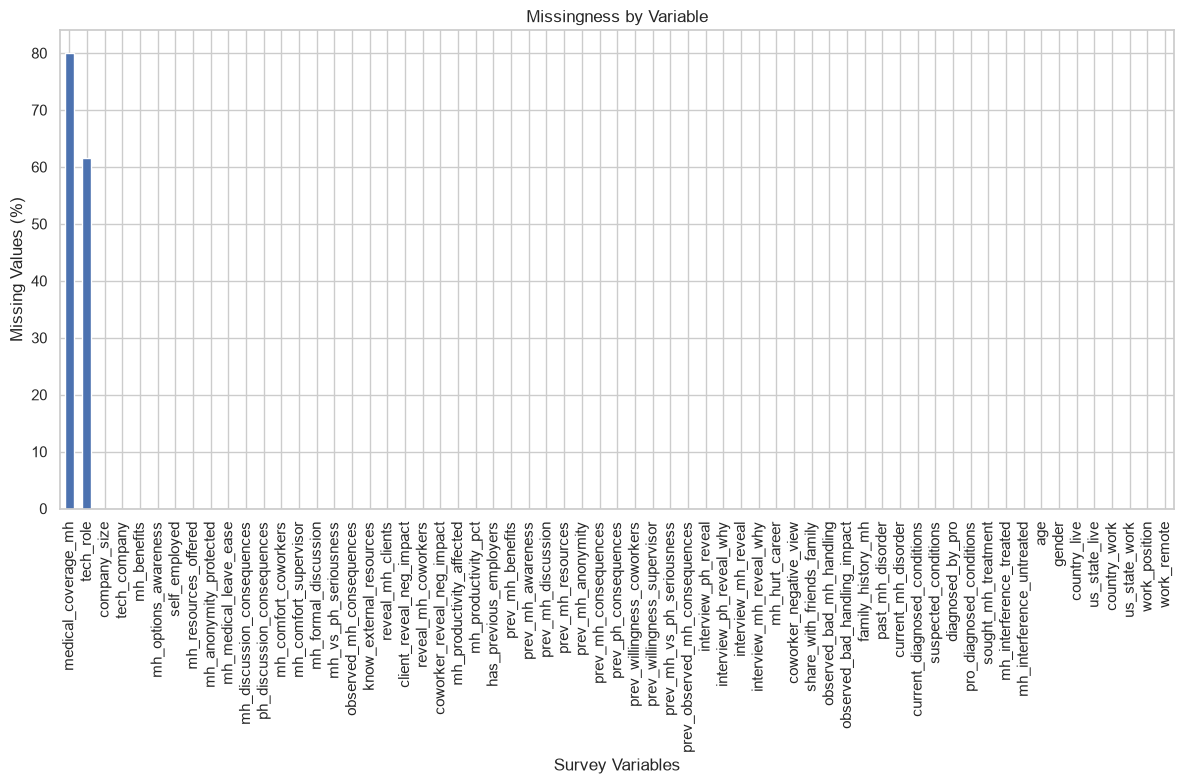

In [41]:
(
    df_clean.isna().mean()
    .sort_values(ascending=False)
    .mul(100)
    .plot(
        kind="bar",
        figsize=(12, 8),
        title="Missingness by Variable"
    )
)

plt.ylabel("Missing Values (%)")
plt.xlabel("Survey Variables")
plt.tight_layout()
plt.show()